In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Adjusting for beatiful graphics
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries were downloaded!")

Libraries were downloaded!


In [2]:
# Reading CSV
df = pd.read_csv('../data/raw/houses_dataset.csv')

# Size + first 5
print(f"Dataset size: {df.shape[0]} building and {df.shape[1]} columns.")
df.head()


Dataset size: 5000 building and 9 columns.


,area_sqm,rooms,floors,distance_city_km,material,has_pool,has_landscape,price_usd,energy_class
0,218.5,6,1,50.5,Brick,0,0,112527.0,B
1,477.8,12,1,74.9,Wood,0,0,363050.0,C
2,379.4,8,1,56.7,Aerated_block,1,0,162867.0,C
3,319.4,9,2,9.2,Aerated_block,1,0,162924.0,C
4,120.2,3,1,19.4,Aerated_block,0,1,44535.0,A


In [3]:
# Group data by materials and calculating avarage price
price_by_material = df.groupby('material')['price_usd'].mean().sort_values()

print("Avarage price by material:")
print(price_by_material)

price_by_pool = df.groupby('has_pool')['price_usd'].mean()
print("\nAvarage price (0 - without pool, 1 - with pool):")
print(price_by_pool)

Avarage price by material:
material
Aerated_block    117646.142572
Brick            169414.489018
Wood             230065.418776
Name: price_usd, dtype: float64

Avarage price (0 - without pool, 1 - with pool):
has_pool
0    137481.301166
1    193236.129936
Name: price_usd, dtype: float64


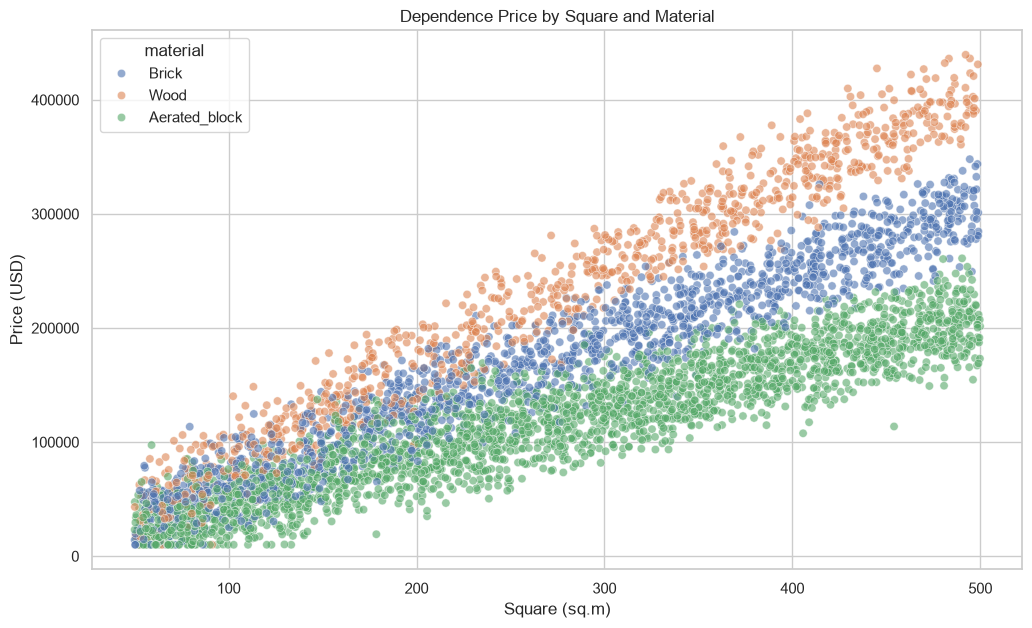

In [4]:
plt.figure(figsize=(12, 7))
sns.scatterplot(data=df, x='area_sqm', y='price_usd', hue='material', alpha=0.6)

plt.title("Dependence Price by Square and Material")
plt.xlabel("Square (sq.m)")
plt.ylabel("Price (USD)")
plt.show()


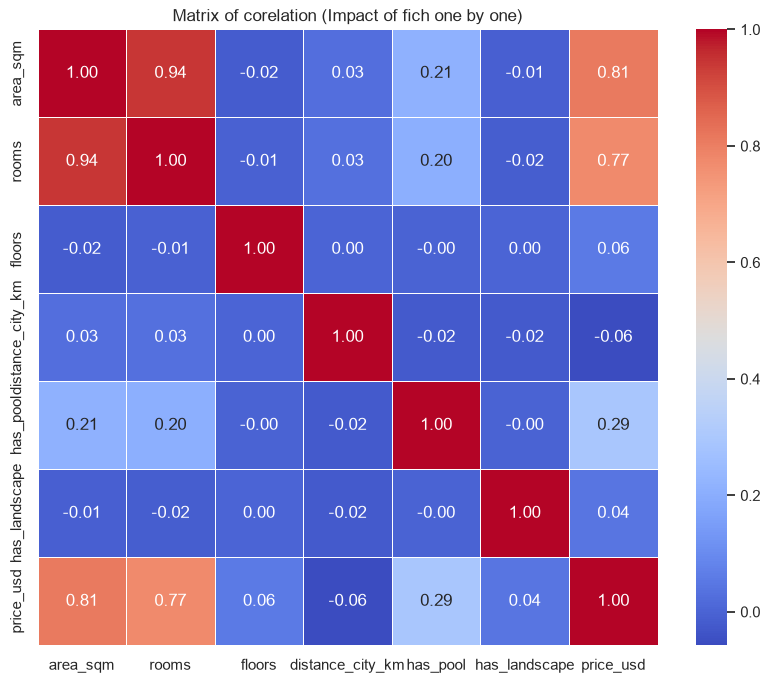

In [5]:
numeric_df = df.select_dtypes(include=['number'])

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Matrix of corelation (Impact of fich one by one)")
plt.show()